### Question 1 ###

In [5]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)

**(a) Add a middle layer (100 nodes, sigmoid)**

In [ ]:
Din, H, K = 3*32*32, 100, 10
std = 1e-2

# Layer 1: input -> 100 hidden nodes
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
# Layer 2: 100 hidden nodes -> 10 outputs
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))

def forward(x):
    h = sigmoid(x.mm(w1) + b1)   # Middle layer with sigmoid activation
    scores = h.mm(w2) + b2       # Output layer
    return h, scores

**(b) Cross entropy loss**

In [ ]:
def softmax(z):
    z = z - z.max(dim=1, keepdim=True).values   
    e = torch.exp(z)
    return e / e.sum(dim=1, keepdim=True)

def cross_entropy(scores, y_onehot):
    N = scores.shape[0]
    p = softmax(scores)
    loss = -(1.0 / N) * torch.sum(y_onehot * torch.log(p + 1e-12))
    return loss, p

def backward(x, h, p, y_onehot):
    N = x.shape[0]
    dscores = (p - y_onehot) / N   # Gradient of cross-entropy + softmax
    dw2 = h.t().mm(dscores)
    db2 = dscores.sum(dim=0)
    dh = dscores.mm(w2.t())
    dz1 = dh * h * (1 - h)   # Sigmoid derivative
    dw1 = x.t().mm(dz1)
    db1 = dz1.sum(dim=0)
    return dw1, db1, dw2, db2

**(c) Run 10 epochs, report train and test accuracy**

Epoch 1/10, Loss: 1.9845
Epoch 2/10, Loss: 1.7925
Epoch 3/10, Loss: 1.7251
Epoch 4/10, Loss: 1.6836
Epoch 5/10, Loss: 1.6543
Epoch 6/10, Loss: 1.6300
Epoch 7/10, Loss: 1.6098
Epoch 8/10, Loss: 1.5918
Epoch 9/10, Loss: 1.5768
Epoch 10/10, Loss: 1.5629


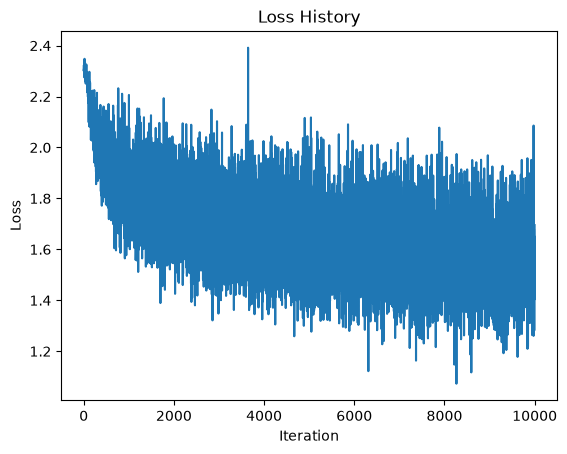

Training accuracy: 46.47%
Test accuracy: 44.91%


In [ ]:
epochs = 10
lr = 5e-2
lr_decay = 0.9
loss_history = []

for t in range(epochs):
    running_loss = 0.0
    for inputs, labels in trainloader:
        N = inputs.shape[0]
        x = inputs.view(N, -1)
        y = nn.functional.one_hot(labels, K).float()

        h, scores = forward(x)
        loss, p = cross_entropy(scores, y)
        loss_history.append(loss.item())
        running_loss += loss.item()

        dw1, db1, dw2, db2 = backward(x, h, p, y)
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t+1}/{epochs}, Loss: {running_loss/len(trainloader):.4f}")
    lr *= lr_decay

# Loss plot
plt.plot(loss_history)
plt.title("Loss History"); plt.xlabel("Iteration"); plt.ylabel("Loss")
plt.show()

# Accuracy
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, scores = forward(x)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")

**Discussion**

- Increasing the learning rate from 0.01 to 0.05 improved test accuracy from 37.08% to 44.91% and reduced the final loss from 1.79 to 1.56, indicating better learning within 10 epochs.

- The second run maintained a lower loss throughout training, starting at 1.98 compared with 2.21 in the first run. This suggests that the higher learning rate enabled faster convergence through larger parameter updates.

- The loss was still decreasing at epoch 10, suggesting that additional training might improve performance. However, further experiments are needed to determine whether more epochs or a different learning rate would be beneficial.

- The second run achieved 46.47% training accuracy and 44.91% test accuracy, a small gap of 1.56 percentage points. This indicates that there is no strong evidence of overfitting at this stage.

- The model achieved only around 45% test accuracy partly because flattening images into one-dimensional vectors loses their spatial structure. Unlike dense networks, CNNs can learn local patterns such as edges, shapes, and neighbouring pixels using local connections and shared weights, often with fewer parameters.

- Cross-entropy loss combined with softmax provides a useful gradient for classification, simplifying the output-layer gradient to \(p-y\), where \(p\) is the predicted probability vector and \(y\) is the one-hot target vector. In contrast, MSE combined with softmax can produce smaller gradients for saturated predictions, potentially slowing learning when predictions are incorrect.

### Question 2 ###

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])

train_ds = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_ds = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=1000, shuffle=False, num_workers=0)

def evaluate(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss, correct, n = 0.0, 0, 0
    preds, labs = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item()
            p = out.argmax(dim=1)
            correct += (p == y).sum().item()
            n += y.size(0)
            preds.append(p.cpu()); labs.append(y.cpu())
    return total_loss / n, 100 * correct / n, torch.cat(preds).numpy(), torch.cat(labs).numpy()

def train_model(model, epochs=10, lr=1e-3):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for ep in range(epochs):
        model.train()
        run_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * y.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            n += y.size(0)
        te_loss, te_acc, _, _ = evaluate(model, test_loader)
        hist["train_loss"].append(run_loss / n)
        hist["train_acc"].append(100 * correct / n)
        hist["test_loss"].append(te_loss)
        hist["test_acc"].append(te_acc)
        print(f"Epoch {ep+1}/{epochs} | train loss {run_loss/n:.4f}, acc {100*correct/n:.2f}% "
              f"| test loss {te_loss:.4f}, acc {te_acc:.2f}%")
    return hist

100.0%
100.0%
100.0%
100.0%


**(a) LeNet-5**

In [ ]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.ReLU(),   # 28x28 -> 28x28
            nn.MaxPool2d(2),                                        # 14x14
            nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),             # 10x10
            nn.MaxPool2d(2))                                        # 5x5
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16*5*5, 120), nn.ReLU(),
            nn.Linear(120, 84), nn.ReLU(),
            nn.Linear(84, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(0)
lenet = LeNet5()
print("LeNet-5 params:", sum(p.numel() for p in lenet.parameters()))
hist_lenet = train_model(lenet, epochs=10)

_, tr_acc, _, _ = evaluate(lenet, torch.utils.data.DataLoader(train_ds, batch_size=1000))
print(f"LeNet-5 final train acc: {tr_acc:.2f}%, test acc: {hist_lenet['test_acc'][-1]:.2f}%")

LeNet-5 params: 61706
Epoch 1/10 | train loss 0.2272, acc 92.99% | test loss 0.0746, acc 97.63%
Epoch 2/10 | train loss 0.0625, acc 97.99% | test loss 0.0458, acc 98.38%
Epoch 3/10 | train loss 0.0453, acc 98.56% | test loss 0.0495, acc 98.42%
Epoch 4/10 | train loss 0.0355, acc 98.87% | test loss 0.0388, acc 98.73%
Epoch 5/10 | train loss 0.0299, acc 99.01% | test loss 0.0335, acc 98.91%
Epoch 6/10 | train loss 0.0255, acc 99.17% | test loss 0.0350, acc 98.84%
Epoch 7/10 | train loss 0.0217, acc 99.29% | test loss 0.0317, acc 99.04%
Epoch 8/10 | train loss 0.0180, acc 99.42% | test loss 0.0342, acc 99.03%
Epoch 9/10 | train loss 0.0167, acc 99.42% | test loss 0.0318, acc 99.02%
Epoch 10/10 | train loss 0.0157, acc 99.52% | test loss 0.0331, acc 99.08%
LeNet-5 final train acc: 99.71%, test acc: 99.08%


**Explanation**

- LeNet-5 achieved 99.71% training accuracy and 99.08% test accuracy with 61,706 parameters.
- Test accuracy increased rapidly, reaching 97.63% in the first epoch and stabilizing around 99% from epoch 7.
- Training loss continued to decrease, while test loss levelled off near 0.03. The small accuracy gap of 0.63 percentage points suggests mild overfitting.

(b) Modern small CNN

In [11]:
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))  # 28->14->7->3
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128*3*3, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(0)
modern = ModernCNN()
print("Modern CNN params:", sum(p.numel() for p in modern.parameters()))
hist_modern = train_model(modern, epochs=10)

_, tr_acc, _, _ = evaluate(modern, torch.utils.data.DataLoader(train_ds, batch_size=1000))
print(f"Modern CNN final train acc: {tr_acc:.2f}%, test acc: {hist_modern['test_acc'][-1]:.2f}%")

Modern CNN params: 104650
Epoch 1/10 | train loss 0.1415, acc 95.67% | test loss 0.0451, acc 98.57%
Epoch 2/10 | train loss 0.0556, acc 98.25% | test loss 0.0340, acc 98.86%
Epoch 3/10 | train loss 0.0428, acc 98.69% | test loss 0.0247, acc 99.23%
Epoch 4/10 | train loss 0.0363, acc 98.83% | test loss 0.0308, acc 98.96%
Epoch 5/10 | train loss 0.0309, acc 99.00% | test loss 0.0248, acc 99.14%
Epoch 6/10 | train loss 0.0267, acc 99.10% | test loss 0.0272, acc 99.15%
Epoch 7/10 | train loss 0.0243, acc 99.19% | test loss 0.0357, acc 98.79%
Epoch 8/10 | train loss 0.0226, acc 99.27% | test loss 0.0254, acc 99.18%
Epoch 9/10 | train loss 0.0190, acc 99.38% | test loss 0.0227, acc 99.28%
Epoch 10/10 | train loss 0.0176, acc 99.40% | test loss 0.0218, acc 99.30%
Modern CNN final train acc: 99.70%, test acc: 99.30%


**Explanation**

- The modern CNN achieved 99.70% training accuracy and 99.30% test accuracy with 104,650 parameters.
- It converged faster than LeNet-5, achieving 98.57% test accuracy in epoch 1 and 99.23% by epoch 3. It also achieved a lower final test loss (0.0218 vs. 0.0331).
- The smaller train–test accuracy gap of 0.40 percentage points suggests good generalization. Dropout and Batch Normalization may have contributed to stable performance.
- Test accuracy fluctuated slightly, dipping to 98.79% at epoch 7, before recovering. Overall, the modern CNN achieved slightly better accuracy with approximately 1.7 times more parameters. Since MNIST is relatively simple, both models performed close to the maximum achievable accuracy.

**(c) per-epoch plots + Confusion matrices**

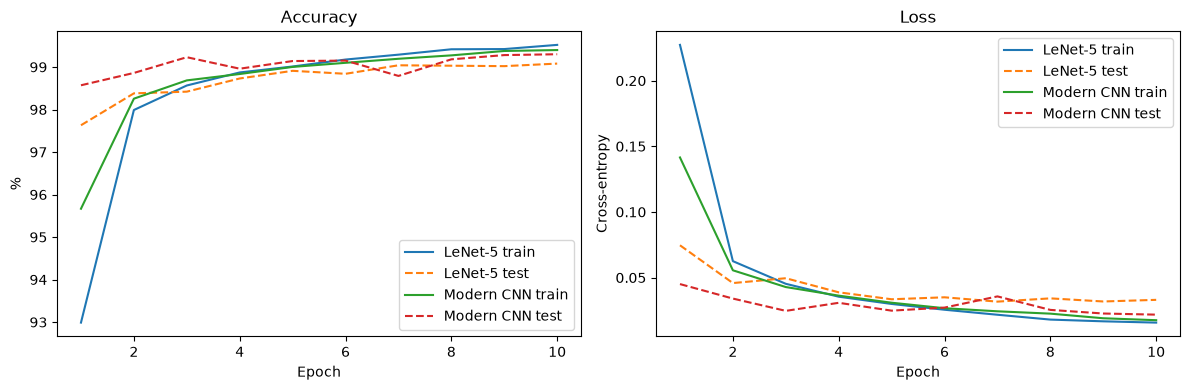

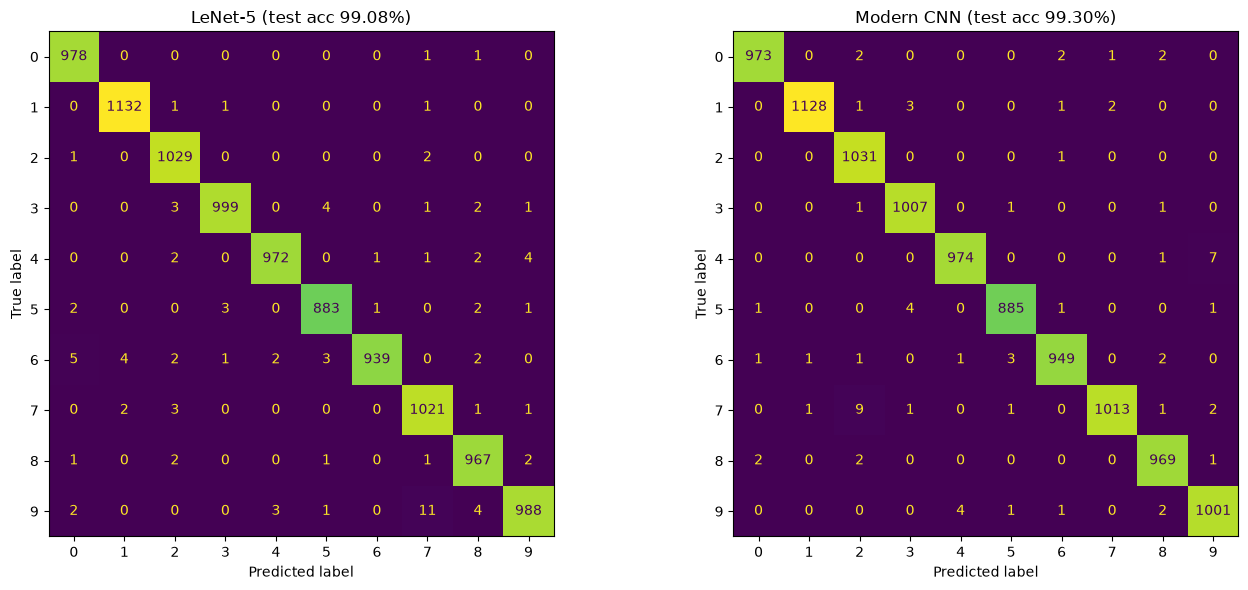

In [12]:
# Accuracy and loss curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ep = range(1, 11)
for name, h in [("LeNet-5", hist_lenet), ("Modern CNN", hist_modern)]:
    ax[0].plot(ep, h["train_acc"], label=f"{name} train")
    ax[0].plot(ep, h["test_acc"], "--", label=f"{name} test")
    ax[1].plot(ep, h["train_loss"], label=f"{name} train")
    ax[1].plot(ep, h["test_loss"], "--", label=f"{name} test")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("%"); ax[0].legend()
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Cross-entropy"); ax[1].legend()
plt.tight_layout(); plt.show()

# Confusion matrices on the test set
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (name, m) in zip(ax, [("LeNet-5", lenet), ("Modern CNN", modern)]):
    _, acc, preds, labs = evaluate(m, test_loader)
    cm = confusion_matrix(labs, preds)
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=a, colorbar=False)
    a.set_title(f"{name} (test acc {acc:.2f}%)")
plt.tight_layout(); plt.show()

**Explanation**
- Learning curves: Both models showed increasing accuracy and decreasing loss during training. The modern CNN generally performed slightly better, while dropout reduced its effective training accuracy during training.
- Confusion matrices: Both models classified most digits correctly, as indicated by the strong diagonal values. The largest off-diagonal entries can be used to identify the most frequently confused digit pairs and compare the errors made by the two models.

### Question 3 ###